# Figure 6: reconstruction quality against the spot filling factor

Section 4.4, `fig:aassim_vs_sff`. The area-adjusted structural
similarity against the true spot filling factor over every surface in
the holdout, as a hexagonal-bin density: the point cloud is 100,000
strong and a scatter would be a solid block, so the count in each cell
carries the shape instead.

Whole-sphere weighting. The filling factor is the area-weighted
fraction of the whole sphere below the 0.9 intensity threshold, the
threshold every detection metric uses. The pass is cached, so
re-running this notebook is immediate.

## Imports

In [1]:
from _setup import *

from starspot_sbi.pipeline import decode_ceiling_coeffs

## Setup

The whole holdout, the chunk size the pass works in, the hexbin
resolution, and the bin occupancy the caption numbers use.

In [2]:
DEVICE = 'cuda'
CHUNK = 2000               # surfaces held in memory at once
GRIDSIZE = 40              # hexagons across the filling-factor axis
MIN_PER_BIN = 50           # surfaces per quantile bin, for the numbers below
CACHE = os.path.join(CACHES, 'fig06_ssim_sff.npz')

## Selecting the sample

Every surface in the holdout index.

In [3]:
idx = load_meta().index.values
print(f'{len(idx):,} holdout surfaces, the whole set')

100,000 holdout surfaces, the whole set


## Inference

Reconstructs every surface at the encoder mean, scores it, and
measures the filling factor of the truth render, one chunk in memory
at a time: the holdout is 100,000 surfaces and the renders would not
fit otherwise.

In [4]:
def score_all():
    """SSIM and true filling factor for the whole holdout, chunk by chunk."""
    vae, stats = load_autoencoder(device=DEVICE)
    w_full = metrics.weights(0.0, *GRID, kind='full')
    ssim = np.empty(len(idx))
    sff = np.empty(len(idx))
    for a in range(0, len(idx), CHUNK):
        b = min(a + CHUNK, len(idx))
        coeffs = np.stack([np.load(os.path.join(HOLDOUT, 'surfaces',
                                                f'surface_{i:07d}.npy'))
                           for i in idx[a:b]])
        truth_real = np.stack([coeffs_to_real(c) for c in coeffs])
        rec = decode_ceiling_coeffs(coeffs, vae, stats, device=DEVICE)
        timgs = render_draws(truth_real, device=DEVICE)
        rimgs = render_draws(rec, device=DEVICE)
        ssim[a:b] = [metrics.ssim_aa_full(timgs[k], rimgs[k])
                     for k in range(b - a)]
        sff[a:b] = [metrics.wmean(metrics.spot_mask(timgs[k]), w_full)
                    for k in range(b - a)]
        print(f'  {b:,} / {len(idx):,}', flush=True)
    return dict(idx=idx, ssim=ssim, sff=sff)


os.makedirs(CACHES, exist_ok=True)
z = np.load(CACHE) if os.path.exists(CACHE) else None
# the guard checks the scored population, not just that a file is there, so a
# different holdout or sample size recomputes instead of being silently reused
if z is not None and z['ssim'].size == len(idx) and np.array_equal(z['idx'],
                                                                   idx):
    d = {k: z[k] for k in z.files}
    print(f'scores read from {os.path.relpath(CACHE, REPO)}')
else:
    d = score_all()                 # the whole holdout; tens of minutes
    np.savez(CACHE, **d)
    print(f'scores written to {os.path.relpath(CACHE, REPO)}')

ssim, sff = d['ssim'], d['sff']
print(f'{ssim.size:,} surfaces, sff range {sff.min():.4f} to '
      f'{sff.max():.4f}')

/home/conaire/miniconda3/envs/paper2_gpu/lib/python3.12/site-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


  2,000 / 100,000
  4,000 / 100,000
  6,000 / 100,000
  8,000 / 100,000
  10,000 / 100,000
  12,000 / 100,000
  14,000 / 100,000
  16,000 / 100,000
  18,000 / 100,000
  20,000 / 100,000
  22,000 / 100,000
  24,000 / 100,000
  26,000 / 100,000
  28,000 / 100,000
  30,000 / 100,000
  32,000 / 100,000
  34,000 / 100,000
  36,000 / 100,000
  38,000 / 100,000
  40,000 / 100,000
  42,000 / 100,000
  44,000 / 100,000
  46,000 / 100,000
  48,000 / 100,000
  50,000 / 100,000
  52,000 / 100,000
  54,000 / 100,000
  56,000 / 100,000
  58,000 / 100,000
  60,000 / 100,000
  62,000 / 100,000
  64,000 / 100,000
  66,000 / 100,000
  68,000 / 100,000
  70,000 / 100,000
  72,000 / 100,000
  74,000 / 100,000
  76,000 / 100,000
  78,000 / 100,000
  80,000 / 100,000
  82,000 / 100,000
  84,000 / 100,000
  86,000 / 100,000
  88,000 / 100,000
  90,000 / 100,000
  92,000 / 100,000
  94,000 / 100,000
  96,000 / 100,000
  98,000 / 100,000
  100,000 / 100,000
scores written to caches/fig06_ssim_sff.npz
100,000 s

In [5]:
# The conditional median and 16-84 band are not drawn: at this sample size
# the density itself shows the trend. They are still reduced here, since the
# Section 4.4 text quotes the endpoints and the spread. Duplicate quantile
# edges are collapsed first: the filling factor ties at the low end, where
# many surfaces have no pixel below the threshold, and a repeated edge would
# otherwise make an empty bin.
edges = np.unique(np.quantile(sff, np.linspace(0, 1,
                                               len(sff) // MIN_PER_BIN + 1)))
which = np.clip(np.searchsorted(edges, sff, side='right') - 1,
                0, len(edges) - 2)
counts = np.array([(which == b).sum() for b in range(len(edges) - 1)])
bins = np.where(counts > 0)[0]
counts = counts[bins]
centres = np.array([sff[which == b].mean() for b in bins])
med = np.array([np.median(ssim[which == b]) for b in bins])
lo = np.array([np.percentile(ssim[which == b], 16) for b in bins])
hi = np.array([np.percentile(ssim[which == b], 84) for b in bins])
print(f'{len(centres)} quantile bins of at least {counts.min()} '
      f'surfaces')


1998 quantile bins of at least 49 surfaces


## Plotting

Draws the figure from the names bound above.

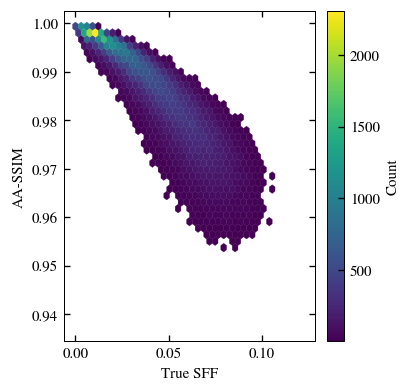

In [8]:
fig, ax = plt.subplots(figsize=(COL, COL * 0.95))
h = ax.hexbin(sff, ssim, gridsize=GRIDSIZE, cmap='viridis', mincnt=10,
              linewidths=0.2)
ax.set_xlabel('True SFF')
ax.set_ylabel('AA-SSIM')
fig.colorbar(h, ax=ax, label='Count')

## Saving and caption numbers

Writes the pdf and png, then prints the numbers the Section 4.4 text
quotes: the endpoints of the decline, whether it is monotonic, and the
spread at fixed filling factor.

In [9]:
save_fig(fig, 'fig06_aassim_vs_sff')
rises = np.sum(np.diff(med) > 0)
print(f'conditional median: {med[0]:.4f} at sff {centres[0]:.4f}, '
      f'{med[-1]:.4f} at sff {centres[-1]:.4f}')
print(f'monotonic decline: {rises} of {len(med) - 1} bin steps rise '
      f'(0 is strictly monotonic)')
print(f'16-84 spread: {hi[0] - lo[0]:.4f} in the lowest bin, '
      f'{hi[-1] - lo[-1]:.4f} in the highest')

wrote notebooks/paper/figs/fig06_aassim_vs_sff.pdf, notebooks/paper/figs/fig06_aassim_vs_sff.png
conditional median: 0.9990 at sff 0.0000, 0.9616 at sff 0.1129
monotonic decline: 996 of 1997 bin steps rise (0 is strictly monotonic)
16-84 spread: 0.0004 in the lowest bin, 0.0125 in the highest
